In [ ]:
#
##NEW DATASET İLE İLGİLİ KOD

import os
import shutil
import kagglehub
import pandas as pd

# 1. Veri setini indir
download_path = kagglehub.dataset_download("naserabdullahalam/phishing-email-dataset")
print("İndirilen geçici klasör:", download_path)

# 2. Klasördeki CSV dosyasını bul
csv_files = [f for f in os.listdir(download_path) if f.endswith('.csv')]
print("Bulunan CSV dosyaları:", csv_files)

# 3. Dosyayı projenin data/ klasörüne 'emails_real.csv' adıyla kopyala
target_dir = "../data"
os.makedirs(target_dir, exist_ok=True)

source_file = os.path.join(download_path, csv_files[0])
target_file = os.path.join(target_dir, "emails_real.csv")

shutil.copy(source_file, target_file)
print(f"Başarıyla kaydedildi -> {target_file}\n")

# 4. İlk kontrol
df = pd.read_csv(target_file)
print("Boyut:", df.shape)
print("Sütunlar:", df.columns.tolist())
print("\nİlk 3 satır:")
display(df.head(3))

100%|██████████| 77.1M/77.1M [00:30<00:00, 2.63MB/s]

Extracting files...


İndirilen geçici klasör: C:\Users\SÜEDA\.cache\kagglehub\datasets\naserabdullahalam\phishing-email-dataset\versions\1
Bulunan CSV dosyaları: ['CEAS_08.csv', 'Enron.csv', 'Ling.csv', 'Nazario.csv', 'Nigerian_Fraud.csv', 'phishing_email.csv', 'SpamAssasin.csv']
Başarıyla kaydedildi -> ../data\emails_real.csv

Boyut: (39154, 7)
Sütunlar: ['sender', 'receiver', 'date', 'subject', 'body', 'label', 'urls']

İlk 3 satır:


,sender,receiver,date,subject,body,label,urls
0,Young Esposito <Young@iworld.de>,user4@gvc.ceas-challenge.cc,"Tue, 05 Aug 2008 16:31:02 -0700",Never agree to be a loser,"Buck up, your troubles caused by small dimensi...",1,1
1,Mok <ipline's1983@icable.ph>,user2.2@gvc.ceas-challenge.cc,"Tue, 05 Aug 2008 18:31:03 -0500",Befriend Jenna Jameson,\nUpgrade your sex and pleasures with these te...,1,1
2,Daily Top 10 <Karmandeep-opengevl@universalnet...,user2.9@gvc.ceas-challenge.cc,"Tue, 05 Aug 2008 20:28:00 -1200",CNN.com Daily Top 10,>+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+...,1,1


In [4]:
# 1. Eksik değer kontrolü
print("Eksik Değerler:")
print(df[['subject', 'body', 'label']].isnull().sum())

# 2. Etiket dağılımı ve formatı
print("\nEtiket Değerleri ve Dağılımı:")
print(df['label'].value_counts(dropna=False))

Eksik Değerler:
subject    28
body        0
label       0
dtype: int64

Etiket Değerleri ve Dağılımı:
label
1    21842
0    17312
Name: count, dtype: int64


Eğitim Verisi: 31323 satır
Test Verisi:   7831 satır

--- YENİ VERİ SETİ: SINIFLANDIRMA RAPORU ---
              precision    recall  f1-score   support

           0     0.9934    0.9934    0.9934      3462
           1     0.9947    0.9947    0.9947      4369

    accuracy                         0.9941      7831
   macro avg     0.9940    0.9940    0.9940      7831
weighted avg     0.9941    0.9941    0.9941      7831

ROC-AUC: 0.9996
PR-AUC:  0.9997


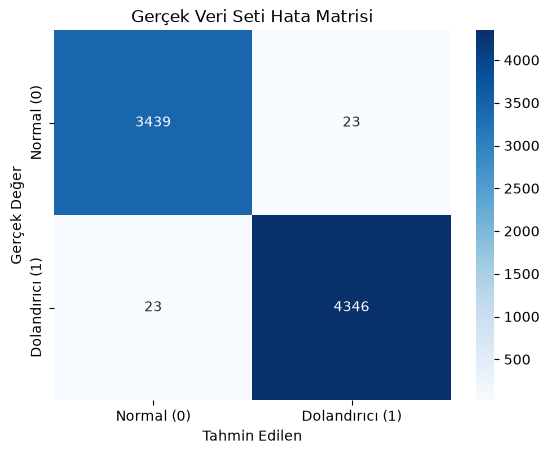

In [5]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, roc_auc_score, average_precision_score, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Metinleri doldur ve birleştir
df['subject'] = df['subject'].fillna('')
df['body'] = df['body'].fillna('')
df['full_text'] = df['subject'] + ' ' + df['body']

# Boş kalan satırları temizle
clean_df = df[df['full_text'].str.strip() != ''].copy()

# Label numerik değilse 0 ve 1'e çevir (Gerekirse)
if clean_df['label'].dtype == 'object':
    clean_df['target'] = clean_df['label'].apply(lambda x: 1 if str(x).lower() in ['1', 'phishing', 'spam', 'fraud'] else 0)
else:
    clean_df['target'] = clean_df['label'].astype(int)

X = clean_df['full_text']
y = clean_df['target']

# 2. Train / Test Ayrımı (%80 Train, %20 Test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Eğitim Verisi: {len(X_train)} satır")
print(f"Test Verisi:   {len(X_test)} satır\n")

# 3. TF-IDF Vektörleştirme
vectorizer = TfidfVectorizer(max_features=5000, stop_words='english', ngram_range=(1, 2))
X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

# 4. Model Eğitimi (Lojistik Regresyon)
model = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)
model.fit(X_train_tfidf, y_train)

# 5. Test Değerlendirmesi
y_pred = model.predict(X_test_tfidf)
y_proba = model.predict_proba(X_test_tfidf)[:, 1]

print("--- YENİ VERİ SETİ: SINIFLANDIRMA RAPORU ---")
print(classification_report(y_test, y_pred, digits=4))
print(f"ROC-AUC: {roc_auc_score(y_test, y_proba):.4f}")
print(f"PR-AUC:  {average_precision_score(y_test, y_proba):.4f}")

# Hata Matrisi Görselleştirme
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Normal (0)', 'Dolandırıcı (1)'],
            yticklabels=['Normal (0)', 'Dolandırıcı (1)'])
plt.xlabel('Tahmin Edilen')
plt.ylabel('Gerçek Değer')
plt.title('Gerçek Veri Seti Hata Matrisi')
plt.show()

0 (Normal): 3462 adet e-posta var.

1 (Dolandırıcı): 4369 adet e-posta var.

precision (Kesinlik / İsabet Oranı):

recall (Duyarlılık / Yakalama Oranı)

#### f1-score: Precision ile Recall değerlerinin harmonik ortalamasıdır. İki metrik arasında bir denge kurulup kurulmadığını özetler (1.0'a ne kadar yakınsa o kadar iyi).

#### Ne Zaman PR-AUC ve F1-Score Bakılır?
Sınıflar arasında uçurum varsa (örneğin verinin %98'i normal, %2'si dolandırıcılık veya nadir bir hastalık).

#### Ne zaman Recall (Duyarlılık)?
Bir şeyi kaçırmanın bedeli çok ağırsa (False Negative maliyeti yüksekse).
Kanser teşhisi, Kritik siber saldırı tespiti
Amaç: Yanlış alarmlar (sağlam birine tetkik yapmak) göze alınır, yeter ki tek bir vaka bile gözden kaçmasın (Recall %99+ hedeflenir).

#### Ne Zaman Precision (Kesinlik)?
Yanlış alarm vermenin bedeli çok ağırsa (False Positive maliyeti yüksekse).
YouTube / Instagram'ın telif veya spam nedeniyle hesap kapatması (Masum bir kullanıcının kanalını yanlışlıkla silersen büyük itibar ve kullanıcı kaybedersin)
Otomatik banka kartı bloke etme (Müşteri market kasasındayken kartını haksız yere kilitlersen müşteri mağdur olur).
Amaç: Model birine "suçlu/dolandırıcı" diyorsa kesinlikle haklı olmalıdır; şüpheli durumlarda müdahale etmemeyi tercih eder (Precision %99+ hedeflenir).

#### Ne Zaman ROC-AUC Bakılır?
* **Durum:** Modelin genel ayrıştırma yeteneğini görmek ve henüz karar eşiğini (0.50 threshold) seçmediğin anlarda.
* **Neden:** ROC-AUC, modelin pozitiflere verdiği skorların negatiflerden yüksek olup olmadığını sıralama mantığıyla ölçer. İki farklı algoritmayı (örneğin XGBoost ile Lojistik Regresyon) genel performans bazında kıyaslamak için en standart metriktir.

### Karar Matrisi Özeti

| Karşılaştığın Senaryo | Bakılacak Ana Metrik | İhmal Edilecek Metrik |
| --- | --- | --- |
| **Sınıflar dengeli (%50 - %50)** | Accuracy, F1-Score | - |
| **Sınıflar dengesiz (%99 - %1)** | PR-AUC, F1-Score, Recall | Accuracy |
| **Kaçırmak yasak (Hastalık, Fraud)** | Recall | Precision |
| **Yanlış suçlamak yasak (Hesap banı)** | Precision | Recall |

#### 1. False Positive = "YALANCI ALARM"
Positive: Alarm bangır bangır çalıyor ("Yangın var!").

False: Ama ortada yangın yok, sadece tost yanmış (Alarm yalan çıktı).

Bizim Projede: Masum, normal bir e-postaya modelin "Bu dolandırıcıdır!" deyip spam kutusuna atması.

#### 2. False Negative = "UYUYAN ALARM" (Kaçırma)
Negative: Alarm tamamen sessiz, hiçbir ses çıkarmıyor ("Sorun yok, temiz").

False: Ama içeride alevler yükseliyor (Alarmın sessiz kalması hata).

Bizim Projede: E-postada gerçek bir dolandırıcı linki varken modelin fark etmeyip "Bu temiz, geçsin" diyerek gelen kutusuna bırakması.

Model ne dedi? (Alarm çaldıysa Positive, sustuysa Negative)

Haklı mıydı? (Haksızsa başına False koy).

In [6]:
# 1. Test verilerini bir araya topla
test_results = pd.DataFrame({
    'text': X_test,
    'true_label': y_test,
    'pred_label': y_pred,
    'fraud_probability': y_proba
})

# 2. Yanlış tahminleri filtrele
false_positives = test_results[(test_results['true_label'] == 0) & (test_results['pred_label'] == 1)]
false_negatives = test_results[(test_results['true_label'] == 1) & (test_results['pred_label'] == 0)]

print(f"Toplam Yanlış Alarm (FP): {len(false_positives)}")
print(f"Toplam Kaçırılan Dolandırıcılık (FN): {len(false_negatives)}")

# 3. Kaçırılan dolandırıcılıklardan 2 örnek görelim
print("\n--- KAÇIRILAN DOLANDIRICILIK ÖRNEKLERİ (False Negatives) ---")
for i, row in false_negatives.head(2).iterrows():
    print(f"\n[Model Olasılığı: %{row['fraud_probability']*100:.1f}]")
    print(row['text'][:400] + "...")

# 4. Yanlışlıkla dolandırıcı sanılan normal e-postalardan 2 örnek
print("\n--- YANLIŞ ALARM ÖRNEKLERİ (False Positives) ---")
for i, row in false_positives.head(2).iterrows():
    print(f"\n[Model Olasılığı: %{row['fraud_probability']*100:.1f}]")
    print(row['text'][:400] + "...")

Toplam Yanlış Alarm (FP): 23
Toplam Kaçırılan Dolandırıcılık (FN): 23

--- KAÇIRILAN DOLANDIRICILIK ÖRNEKLERİ (False Negatives) ---

[Model Olasılığı: %18.6]
North korea nuclear fallout Microsoft gains Yahoo http://schmitt-fotodesign.de/about.html

No virus found in this outgoing message.
Checked by AVG - http://www.avg.com
Version: 8.0.138 / Virus Database: 270.4.11/1554 - Release Date: 7/15/2008 6:03 PM

...

[Model Olasılığı: %1.1]
message undeliverable Sorry, but the craigslist user address you recently mailed (job-222558098@craigslist.org) does not seem to be valid. It could be you're trying to respond to a very old posting, or that the user has not requested anonymous email forwarding. Please check the address and try again. ---- The original headers appear below this line ---- Received: from 213-140-18-139.fastres.net (2...

--- YANLIŞ ALARM ÖRNEKLERİ (False Positives) ---

[Model Olasılığı: %63.2]
Pharmacy Direct - Gluten Free Products and Dr Rodney Fords Books  

 	
Home
 	 Pr

In [7]:
feature_names = np.array(vectorizer.get_feature_names_out())
coefs = model.coef_[0]

top_fraud = pd.Series(coefs, index=feature_names).sort_values(ascending=False).head(10)
top_legit = pd.Series(coefs, index=feature_names).sort_values(ascending=True).head(10)

print("--- DOLANDIRICI OLMAYI TETİKLEYEN EN GÜÇLÜ 10 KELİME ---")
print(top_fraud)

print("\n--- NORMAL OLMAYI TETİKLEYEN EN GÜÇLÜ 10 KELİME ---")
print(top_legit)

--- DOLANDIRICI OLMAYI TETİKLEYEN EN GÜÇLÜ 10 KELİME ---
com        5.080746
love       5.053882
http       4.165336
men        4.064217
cnn        3.493767
health     3.413901
replica    3.141922
life       3.111624
payment    3.039779
watches    3.008408
dtype: float64

--- NORMAL OLMAYI TETİKLEYEN EN GÜÇLÜ 10 KELİME ---
wrote      -7.178508
org        -6.140446
opensuse   -5.506857
python     -4.818623
rant       -4.650052
10         -4.425026
2007       -4.382156
perl       -4.134724
thanks     -4.128098
postfix    -3.738851
dtype: float64


In [8]:
from sklearn.metrics import precision_score, recall_score, f1_score

# Farklı karar eşiklerini deneyelim
thresholds = [0.30, 0.40, 0.50, 0.60, 0.70, 0.80, 0.90]
results = []

for t in thresholds:
    preds = (y_proba >= t).astype(int)
    fp = ((preds == 1) & (y_test == 0)).sum()
    fn = ((preds == 0) & (y_test == 1)).sum()
    
    results.append({
        'Eşik (Threshold)': t,
        'Yanlış Alarm (FP)': fp,
        'Kaçan Dolandırıcı (FN)': fn,
        'Precision': round(precision_score(y_test, preds), 4),
        'Recall': round(recall_score(y_test, preds), 4),
        'F1-Score': round(f1_score(y_test, preds), 4)
    })

threshold_df = pd.DataFrame(results)
print("--- KARAR EŞİĞİ (THRESHOLD) ANALİZİ ---")
print(threshold_df.to_string(index=False))

--- KARAR EŞİĞİ (THRESHOLD) ANALİZİ ---
 Eşik (Threshold)  Yanlış Alarm (FP)  Kaçan Dolandırıcı (FN)  Precision  Recall  F1-Score
              0.3                 68                      10     0.9846  0.9977    0.9911
              0.4                 38                      14     0.9913  0.9968    0.9941
              0.5                 23                      23     0.9947  0.9947    0.9947
              0.6                 15                      38     0.9965  0.9913    0.9939
              0.7                  8                      74     0.9981  0.9831    0.9905
              0.8                  4                     140     0.9991  0.9680    0.9833
              0.9                  3                     361     0.9993  0.9174    0.9566


##### Gerçek veri biliminde *amaç*

Hata türlerini iş hedefine göre yönetilebilir seviyeye indirmek.

Modelin kelime ezberine olan bağımlılığını kırıp onu aldatmacalara (sahte antivirüs damgası, IP içeren gizli linkler vb.) karşı daha dirençli hale getirmektir

In [9]:
import re
import numpy as np
import pandas as pd
from scipy.sparse import hstack
from sklearn.preprocessing import StandardScaler

# 1. Yeni Sayısal Özellikleri (Features) Çıkaralım
def extract_meta_features(df_subset):
    features = pd.DataFrame(index=df_subset.index)
    
    # Karakter ve kelime sayıları
    features['char_count'] = df_subset['full_text'].apply(len)
    features['word_count'] = df_subset['full_text'].apply(lambda x: len(x.split()))
    
    # Büyük harf oranı (Bağıran metinler)
    features['caps_ratio'] = df_subset['full_text'].apply(
        lambda x: sum(1 for c in x if c.isupper()) / (len(x) + 1)
    )
    
    # Ünlem ve dolar işareti sıklığı
    features['exclamation_count'] = df_subset['full_text'].apply(lambda x: x.count('!'))
    features['dollar_count'] = df_subset['full_text'].apply(lambda x: x.count('$'))
    
    # Link (URL) sayısı tespiti
    features['url_count'] = df_subset['full_text'].apply(
        lambda x: len(re.findall(r'https?://[^\s<>"]+|www\.[^\s<>"]+', x))
    )
    
    # IP adresi içeren link var mı? (1 veya 0)
    features['has_ip_url'] = df_subset['full_text'].apply(
        lambda x: 1 if re.search(r'https?://\d{1,3}\.\d{1,3}\.\d{1,3}\.\d{1,3}', x) else 0
    )
    
    return features

# Eğitim ve test için özellikleri hesapla
print("Yeni özellikler çıkarılıyor...")
meta_train = extract_meta_features(clean_df.loc[X_train.index])
meta_test = extract_meta_features(clean_df.loc[X_test.index])

# Sayısal özellikleri ölçeklendir (Standartlaştırma)
scaler = StandardScaler()
meta_train_scaled = scaler.fit_transform(meta_train)
meta_test_scaled = scaler.transform(meta_test)

# 2. TF-IDF Matrisi ile Yeni Özellikleri Birleştir (Stacking)
X_train_combined = hstack([X_train_tfidf, meta_train_scaled])
X_test_combined = hstack([X_test_tfidf, meta_test_scaled])

print(f"Eski Girdi Boyutu (Sadece TF-IDF): {X_train_tfidf.shape[1]}")
print(f"Yeni Birleşik Girdi Boyutu: {X_train_combined.shape[1]}")

# 3. Modeli Yeni Birleşik Veriyle Tekrar Eğit
model_v2 = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)
model_v2.fit(X_train_combined, y_train)

# 4. Yeni Sonuçları Değerlendir
y_pred_v2 = model_v2.predict(X_test_combined)
y_proba_v2 = model_v2.predict_proba(X_test_combined)[:, 1]

cm_v2 = confusion_matrix(y_test, y_pred_v2)
fp_v2 = cm_v2[0, 1]
fn_v2 = cm_v2[1, 0]

print(f"\n--- YENİ MODEL SONUCU ---")
print(f"Eski Model Hataları -> FP: 23, FN: 23")
print(f"Yeni Model Hataları -> FP: {fp_v2}, FN: {fn_v2}")

Yeni özellikler çıkarılıyor...
Eski Girdi Boyutu (Sadece TF-IDF): 5000
Yeni Birleşik Girdi Boyutu: 5007

--- YENİ MODEL SONUCU ---
Eski Model Hataları -> FP: 23, FN: 23
Yeni Model Hataları -> FP: 21, FN: 18


In [11]:
# Son 7 katsayı yeni eklediğimiz meta-özelliklere aittir
meta_feature_names = ['char_count', 'word_count', 'caps_ratio', 'exclamation_count', 'dollar_count', 'url_count', 'has_ip_url']
meta_coefficients = model_v2.coef_[0][-7:]

meta_importance = pd.DataFrame({
    'Özellik': meta_feature_names,
    'Katsayı (Ağırlık)': meta_coefficients
}).sort_values(by='Katsayı (Ağırlık)', ascending=False)

print("--- YENİ EKLENEN ÖZELLİKLERİN ETKİSİ ---")
print(meta_importance.to_string(index=False))

--- YENİ EKLENEN ÖZELLİKLERİN ETKİSİ ---
          Özellik  Katsayı (Ağırlık)
exclamation_count           0.409548
       has_ip_url           0.001071
       caps_ratio          -0.131774
        url_count          -0.334862
     dollar_count          -0.836207
       word_count          -1.739243
       char_count          -2.942134
